# German reunification

GDP per capita, 1960–2003; first comparison post-period 1990. Outcome: GDP per capita in PPP-adjusted current US dollars, following the authors' 2025 erratum.

Historical results and matched reproductions are annotated directly on the figures. Expand the notes and audit tables for full specifications and numerical checks.

<details>
<summary>Historical specification and source</summary>

Abadie, Diamond and Hainmueller (2015), [AJPS](https://doi.org/10.1111/ajps.12116). The paper reports that reunification reduced West Germany’s annual GDP per capita by approximately US$1,600 on average over 1990–2003. The historical two-stage predictor-weight specification includes 1990 in predictor means and in the training validation window. We retain this historical convention explicitly; all common-comparison models below fit only years **strictly before 1990**.

</details>

<details>
<summary>Setup, data and figure exports</summary>

Run from a checkout installed using `requirements-replication.txt` and `pip install -e .`. Full execution also needs the separately supplied local reference bundle, which is excluded from this repository. Once it is provisioned, install the original R dependencies with `python .local/reference/scripts/install_r_references.py --library .r-library` after following [the R setup guide](../docs/reference_backends.md). The notebook downloads immutable public data with **requests**, checks the reference specification, and exports five publication figures locally as PDF, SVG and 300 dpi PNG. Figures, result tables and diagnostics are written under `outputs/empirical_examples/germany/` relative to the checkout root. See [the replication guide](../docs/replication.md) and [the figure guide](../docs/plotting.md).

</details>

In [1]:
%matplotlib inline
import hashlib
import json
import time
import warnings
from collections import Counter
from dataclasses import replace
from functools import partial
from html import escape
from io import BytesIO
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

from pysynth import (
    SyntheticControl, SCUL, IndividualSC, TwoStageIndividualSC,
    SyntheticDID, DifferenceInDifferences, PredictorSyntheticControl,
    AugmentedSyntheticControl, PenalizedSyntheticControl, RobustSyntheticControl,
    DifferencedSyntheticControl, compare,
    plot_paths, plot_effects, plot_comparison, save_figure,
    select_estimator, donor_sensitivity, plot_backtest, plot_donor_sensitivity,
)
from pysynth.datasets import DATASETS
from pysynth.replication import (
    LITERATURE_BENCHMARKS, replicate, check_replication, reference_comparisons,
    california_paper_inference,
)
from pysynth.plotting import reference_comparison_table

versions = pd.Series({p: version(p) for p in [
    'pysynth-control', 'numpy', 'scipy', 'pandas', 'matplotlib',
    'pysyncon', 'SyntheticControlMethods',
]}, name='version').rename_axis('package')
versions

package
pysynth-control             0.1.0
numpy                       2.0.2
scipy                      1.13.1
pandas                      2.3.3
matplotlib                  3.9.4
pysyncon                    1.7.0
SyntheticControlMethods    1.1.17
Name: version, dtype: object

## Download and verify the academic data

The URL names an immutable upstream commit. SHA256 verification fails
visibly if the bytes differ. No manual download or bundled data is required.

In [2]:
name = 'germany'
spec = DATASETS[name]
response = requests.get(spec.url, timeout=30)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == spec.sha256
data = pd.read_csv(BytesIO(response.content), sep=spec.separator)
panel = spec.panel(data)
print(spec.citation)
print(spec.url)
print(f'{panel.n_control} donors; {panel.n_pre} pre-periods; {panel.n_post} post-periods')

Abadie, Diamond & Hainmueller (2015), doi:10.1111/ajps.12116
https://raw.githubusercontent.com/sdfordham/pysyncon/b77dc20e29b012ab03ca1d4caeef7b41861e86f5/data/germany.csv
16 donors; 30 pre-periods; 14 post-periods


## Reference specification and numerical check

The figure pairs each source result with its matched reproduction.
Historical specifications and their numerical checks are separate from
the common-sample applications below.

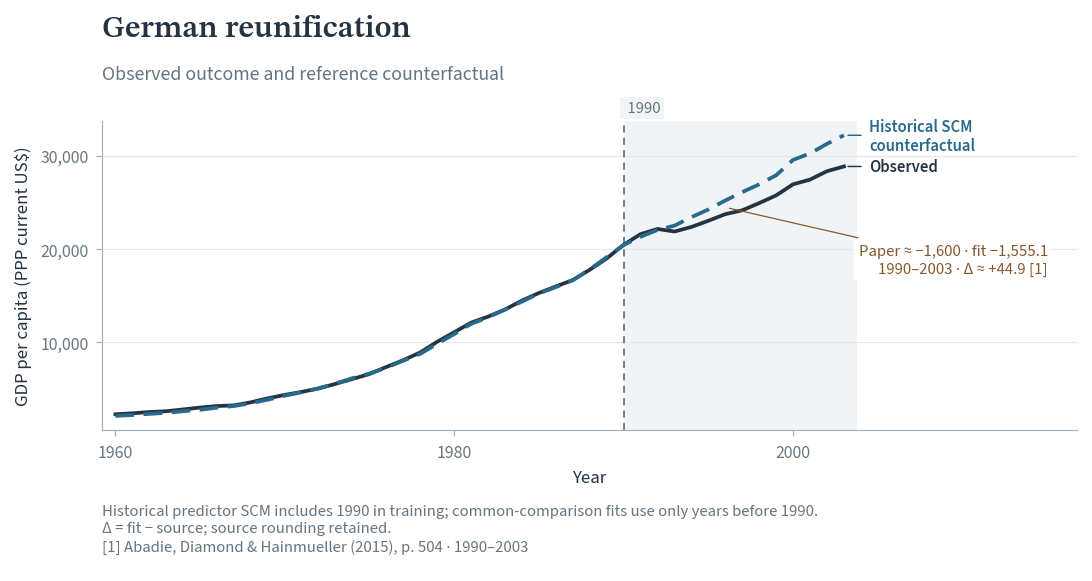

Project exports · `outputs/empirical_examples/germany/germany-reference.pdf` · `outputs/empirical_examples/germany/germany-reference.svg` · `outputs/empirical_examples/germany/germany-reference.png` · [Literature source](https://economics.mit.edu/sites/default/files/publications/Comparative%20Politics%20and%20the%20Synthetic%20Control.pdf#page=10)

In [3]:
figure_details = {'case': 'German reunification', 'outcome': 'GDP per capita (PPP current US$)', 'effect': 'Effect on GDP per capita (PPP current US$)', 'units': 'PPP current US$ per capita', 'periods': '1960–1989 pretreatment · 1990–2003 post-treatment · 16 donors', 'onset': '1990', 'reference': 'Historical SCM counterfactual', 'reference_note': 'Historical predictor SCM includes 1990 in training; common-comparison fits use only years before 1990.', 'comparison_note': 'Historical SCM includes 1990 in predictor training; common-comparison fits use only years before 1990.'}
benchmark = LITERATURE_BENCHMARKS[name]
cwd = Path.cwd()
root = cwd.parent if cwd.name == 'empirical_examples' else cwd
output_dir = root / 'outputs' / 'empirical_examples' / name
output_dir.mkdir(parents=True, exist_ok=True)
versions.to_csv(output_dir / f'{name}-versions.csv')
warning_rows = []

def export_figure(fig, kind):
    paths = save_figure(fig, output_dir / f'{name}-{kind}')
    paths_text = ' · '.join(f'`{p.relative_to(root).as_posix()}`' for p in paths)
    display(Markdown('Project exports · ' + paths_text + f' · [Literature source]({benchmark.source_url})'))
    return paths

def display_audit(title, *tables):
    tables_html = ''.join(
        (table.to_frame() if isinstance(table, pd.Series) else table).to_html(escape=True)
        for table in tables
    )
    display(HTML(f'<details><summary>{escape(title)}</summary>{tables_html}</details>'))

def display_warnings(section, records):
    if records:
        counts = Counter((w.category.__name__, str(w.message)) for w in records)
        rows = [(kind, message, count) for (kind, message), count in counts.items()]
        warning_rows.extend((section, *row) for row in rows)
        display_audit(f'{section} warnings ({len(records)} emitted)',
                      pd.DataFrame(rows, columns=['Category', 'Message', 'Count']))

with warnings.catch_warnings(record=True) as reference_warnings:
    reference = replicate(name, data)
    report = check_replication(name, reference)
    additional = None
    paper_uncertainty = None
    if name == 'california':
        additional = {'SC': SyntheticDID().fit_sc(panel), 'DID': DifferenceInDifferences().fit(panel)}
        paper_uncertainty = california_paper_inference(panel, reference)
        se_reference = paper_uncertainty.metadata['paper_replication']['reference_standard_error']
        np.testing.assert_allclose(paper_uncertainty.standard_error, se_reference, atol=1e-9, rtol=0)
        assert abs(additional['SC'].att - (-19.6)) <= 0.05
        assert abs(additional['DID'].att - (-27.3)) <= 0.05
        report.update({'SE estimate': paper_uncertainty.standard_error,
                       'SE reference': se_reference, 'SE absolute tolerance': 1e-9})
def matched_references(fit, additional=None):
    refs = reference_comparisons(name, fit, additional=additional)
    if paper_uncertainty is not None:
        refs = [replace(r, context=r.context + (
            f' SE: paper 8.4; reproduced {paper_uncertainty.standard_error:.3f} '
            '(authors’ seed 12345).'
        )) if r.label == 'SDID' else r for r in refs]
    return refs

references = matched_references(reference, additional=additional)
reference_table = reference_comparison_table(references)
reference_table.to_csv(output_dir / f'{name}-references.csv', index=False)
replication_checks = pd.Series(report, name='Replication check')
replication_checks.to_csv(output_dir / f'{name}-replication-checks.csv', index_label='statistic')
ax = plot_paths(
    reference,
    title=figure_details['case'],
    subtitle='Observed outcome and reference counterfactual',
    ylabel=figure_details['outcome'], xlabel='Year',
    observed_label='Observed',
    counterfactual_label=figure_details['reference'],
    intervention_label=figure_details['onset'],
    references=references,
    note=figure_details['reference_note'],
)
plt.show()
reference_files = export_figure(ax.figure, 'reference')
display_warnings('Historical fit and paper inference', reference_warnings)
display_audit('Reference values and numerical replication checks',
              reference_table, replication_checks)

## Fit all applicable methods on a common sample

All methods share the outcome panel, eligible donors and treatment date. These are new applications, distinct from the historical replications.

<details>
<summary>Estimator specifications and full computation settings</summary>

**Outcome SCM** minimizes equally weighted squared gaps across all
pretreatment periods. **Predictor SCM** matches three predictors: the
mean outcome in each of three consecutive, nearly equal-length blocks
of pretreatment dates. Its nested fit chooses predictor importance using
error across the full pretreatment path. The three-block design is a
prespecified application of classical SCM in these comparisons.
[Abadie, Diamond and Hainmueller (2010)](https://doi.org/10.1198/jasa.2009.ap08746)

**Ridge-augmented SCM** uses a ridge outcome model to adjust for
remaining pretreatment imbalance. The penalty is chosen by
pretreatment cross-validation.
[Ben-Michael, Feller and Rothstein (2021)](https://doi.org/10.1080/01621459.2021.1929245)

**Penalized SCM** matches pretreatment outcomes with a penalty on
the distance from the treated unit to each contributing donor.
The comparison fixes the pairwise penalty at 0.01.
[Abadie and L’Hour (2021)](https://doi.org/10.1080/01621459.2021.1971535)

**Robust SCM** denoises the full donor outcome matrix, fits weights
by ridge regression against pretreatment treated outcomes, and predicts
with the denoised donors. Here the rank is three and the ridge penalty
is 0.1. Both penalized and robust SCM use study-design tuning choices
for these applications.
[Amjad, Shah and Shen (2018)](https://jmlr.org/papers/v19/17-777.html)

**Differenced SCM** targets pretreatment changes and restores the
mean pretreatment level gap when predicting the untreated path.
This application uses all pretreatment outcome lags as level predictors,
ten optimizer starts, and the zero-penalty specification. It uses
the full pretreatment period for fitting. The working paper also
considers tuning by a training/validation split.
[Engelbrektson (2021 working paper), §4 and Table 2](https://arxiv.org/abs/2111.10784)

SCUL calls the pinned original R functions and glmnet, selecting
`lambda.median` from fold-specific paths. Its original near-zero-variance
screening checks the full series and each training window, so data
admissibility can depend on post-period values; lasso fitting and
penalty selection use only pretreatment outcomes. Rolling windows
are stated in code. Basque has only ten pretreatment observations, so
its validation horizon must be shorter than its 28-period post window.

ISC calls **MSCMT**, using the costofcare bootstrap workflow with **50
donor resamples**. 2SISC follows Petrillo et al. (2025): raw nearest-neighbor
screening followed by nested SCM on temporal predictor means, without
donor resampling. `n_neighbors=10` counts ten donors; the authors' KDTree
implementation counts the treated case in its query size. The earlier
MSCMT/50-draw two-stage variant remains explicitly available through
`backend='mscmt', n_bootstrap=50`. These aggregate panels
do not provide the survey-specific demographic predictors, eligibility
rules, or individual sampling design of the original ISC studies.

SDID uses post-period donor outcomes to estimate time weights.
Each model runs in full. The exports include elapsed fitting times
and optimizer diagnostics alongside the estimates.

</details>

In [4]:
scul_windows = {'california': (5, 12), 'basque': (3, 5),
                'germany': (14, 14), 'kansas': (16, 16)}
initial, horizon = scul_windows[name]
pre_dates = panel.times[:panel.n_pre].to_numpy()
predictor_windows = [block.tolist() for block in np.array_split(pre_dates, 3)]
models = {
    'Outcome SCM': SyntheticControl(),
    'Predictor SCM (three pre-period means)': PredictorSyntheticControl(
        predictor_windows=predictor_windows,
    ),
    'Ridge-augmented SCM': AugmentedSyntheticControl(),
    'Penalized SCM (0.01)': PenalizedSyntheticControl(lambda_=0.01),
    'Robust SCM (rank 3, ridge 0.1)': RobustSyntheticControl(sv_count=3, lambda_=0.1),
    'Differenced SCM': DifferencedSyntheticControl(),
    'SCUL': SCUL(initial_window=initial, horizon=horizon),
    'ISC (full donor pool)': IndividualSC(),
    '2SISC (nearest 10)': TwoStageIndividualSC(n_neighbors=10),
    'Synthetic DID': SyntheticDID(),
    'DID': DifferenceInDifferences(),
}
results, elapsed = {}, {}
with warnings.catch_warnings(record=True) as comparison_warnings:
    for label, model in models.items():
        started = time.perf_counter()
        results[label] = model.fit(panel)
        elapsed[label] = time.perf_counter() - started
print(f'Fitted {len(results)} estimators on the common panel.')
comparison = compare(results)
comparison['elapsed_seconds'] = pd.Series(elapsed)
if name == 'california':
    references = matched_references(results['Synthetic DID'], additional={
        'SC': additional['SC'], 'DID': results['DID'],
    })
elif name == 'kansas':
    references = matched_references(results['Ridge-augmented SCM'])
diagnostics = {label: fit.metadata for label, fit in results.items()}
(output_dir / f'{name}-diagnostics.json').write_text(
    json.dumps(diagnostics, indent=2, default=str) + chr(10)
)
display_labels = {
    'ISC (full donor pool)': 'ISC · full donor pool',
    '2SISC (nearest 10)': '2SISC · nearest 10',
    'Predictor SCM (three pre-period means)': 'Predictor SCM · 3 blocks',
    'Penalized SCM (0.01)': 'Penalized SCM · λ = 0.01',
    'Robust SCM (rank 3, ridge 0.1)': 'Robust SCM · rank 3',
}

Fitted 11 estimators on the common panel.


## Average effects and pretreatment fit

Source comparisons use matched statistics and evaluation windows;
they are not targets for every estimator. Dots are point estimates without
confidence intervals.

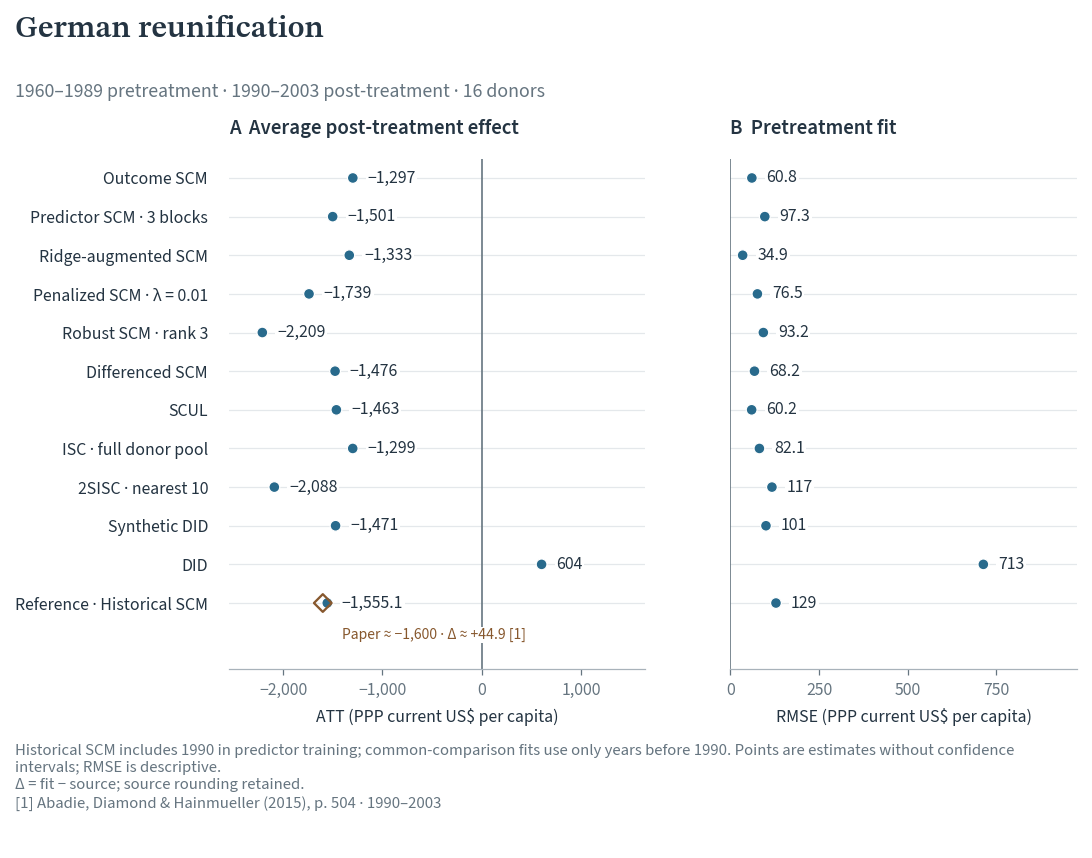

Project exports · `outputs/empirical_examples/germany/germany-comparison.pdf` · `outputs/empirical_examples/germany/germany-comparison.svg` · `outputs/empirical_examples/germany/germany-comparison.png` · [Literature source](https://economics.mit.edu/sites/default/files/publications/Comparative%20Politics%20and%20the%20Synthetic%20Control.pdf#page=10)

,Category,Message,Count
0,RuntimeWarning,SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata,1


,att,pre_rmse,donors_used,weight_sum,elapsed_seconds
model,,,,,
Outcome SCM,-1297.4732,60.8444,7,1.0000,0.0041
Predictor SCM (three pre-period means),-1500.5308,97.3299,13,1.0000,10.0162
Ridge-augmented SCM,-1333.1145,34.8796,16,1.0000,0.4255
Penalized SCM (0.01),-1738.6838,76.5068,5,1.0000,0.0919
"Robust SCM (rank 3, ridge 0.1)",-2209.0491,93.2023,16,1.1385,0.0003
Differenced SCM,-1476.3545,68.1846,9,1.0000,9.1609
SCUL,-1463.2094,60.2132,8,1.0058,0.6120
ISC (full donor pool),-1298.5680,82.1369,14,1.0000,0.5950
2SISC (nearest 10),-2088.1751,117.4281,10,1.0000,0.0200


In [5]:
fig, axes = plot_comparison(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle=figure_details['periods'],
    units=figure_details['units'],
    references=references,
    note=figure_details['comparison_note'] + ' Points are estimates without confidence intervals; RMSE is descriptive.',
)
comparison.to_csv(output_dir / f'{name}-estimates.csv')
plt.show()
comparison_files = export_figure(fig, 'comparison')
display_warnings('Estimator comparison', comparison_warnings)
display_audit('Estimator estimates, pretreatment fit and elapsed times', comparison.round(4))

## Effect paths on a common scale

Comparison and reference specifications show **observed minus counterfactual** on shared scales.
Numeric reference guides apply only to their matched estimators.

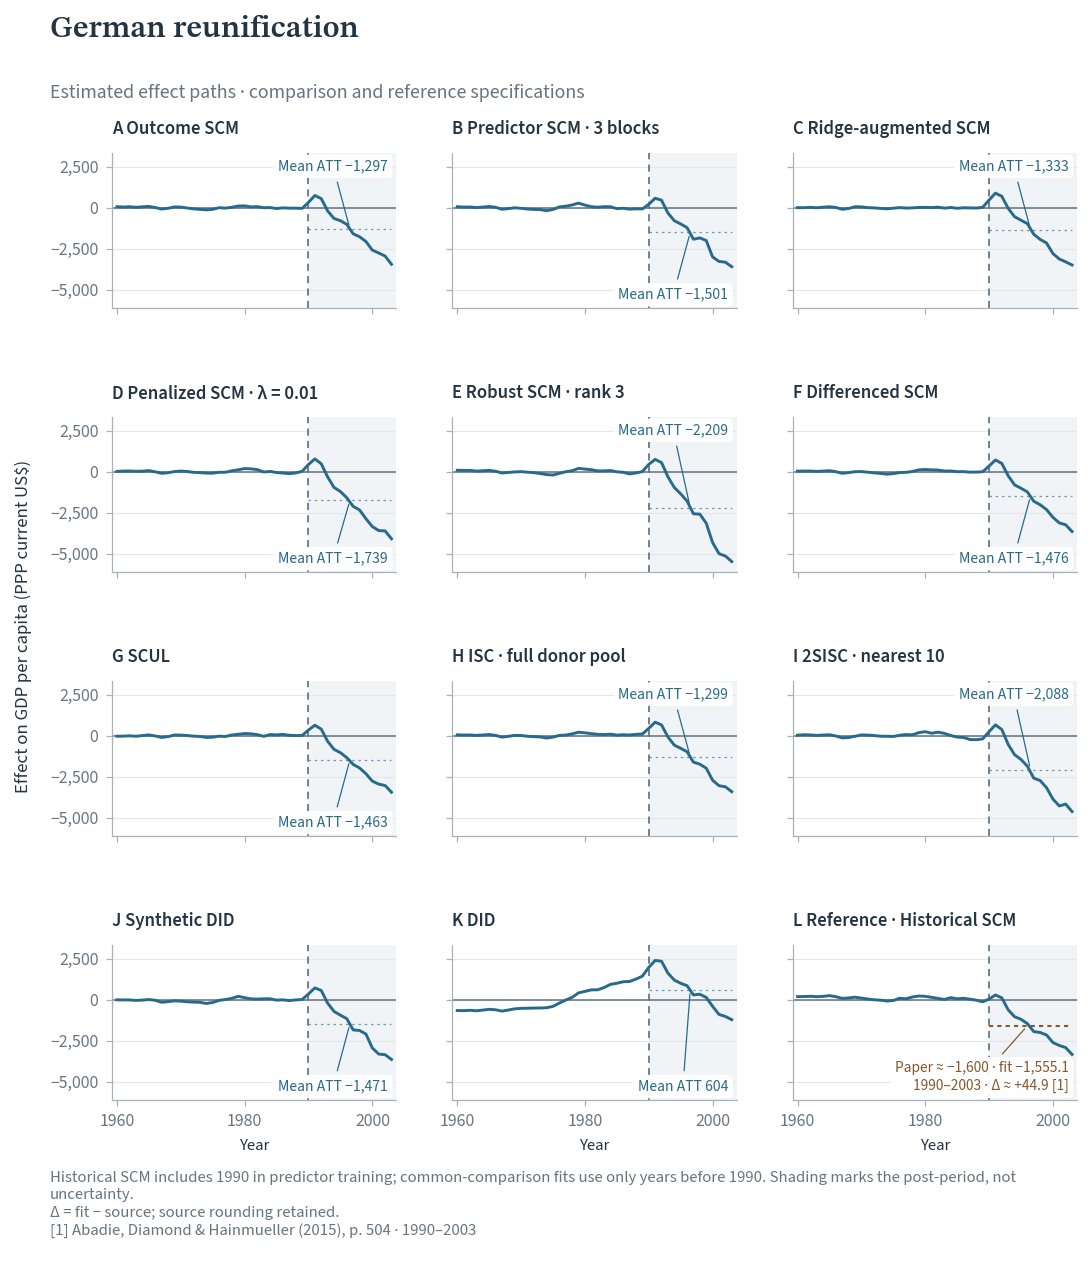

Project exports · `outputs/empirical_examples/germany/germany-effects.pdf` · `outputs/empirical_examples/germany/germany-effects.svg` · `outputs/empirical_examples/germany/germany-effects.png` · [Literature source](https://economics.mit.edu/sites/default/files/publications/Comparative%20Politics%20and%20the%20Synthetic%20Control.pdf#page=10)

In [6]:
fig, axes = plot_effects(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle='Estimated effect paths · comparison and reference specifications',
    ylabel=figure_details['effect'], xlabel='Year',
    references=references,
    note=figure_details['comparison_note'] + ' Shading marks the post-period, not uncertainty.',
)
plt.show()
effects_files = export_figure(fig, 'effects')

## Pretreatment validation and specification selection

Common pretreatment holdouts compare prediction performance. Selection does not establish causal validity; the selected score is optimistic.

<details>
<summary>Validation design, selection and limitations</summary>

These are **new analyses of the academic data**, separate from the paper
replications above. We compare methods and three prespecified 2SISC donor
counts on common withheld pretreatment blocks. Every actual post-treatment
row is excluded from validation. Held-out treated outcomes are masked
during fitting; contemporaneous donor outcomes remain available.

SCUL keeps its original internal rolling windows, so the outer training
sample must be long enough to contain them. Short panels consequently
offer only a few validation folds: this is a transparent illustration,
not strong evidence that the selected estimator is generally superior.
Every fit retains the estimator's full optimization and resampling settings.
SCUL's full-series admissibility screen sees the masked target series here.

Selection minimizes pooled held-out RMSE, then fits the winner on the
original panel. The selected score is optimistic after model selection;
no post-selection confidence interval or causal guarantee is implied.
Candidate choices and folds must be set before examining treatment effects.

</details>

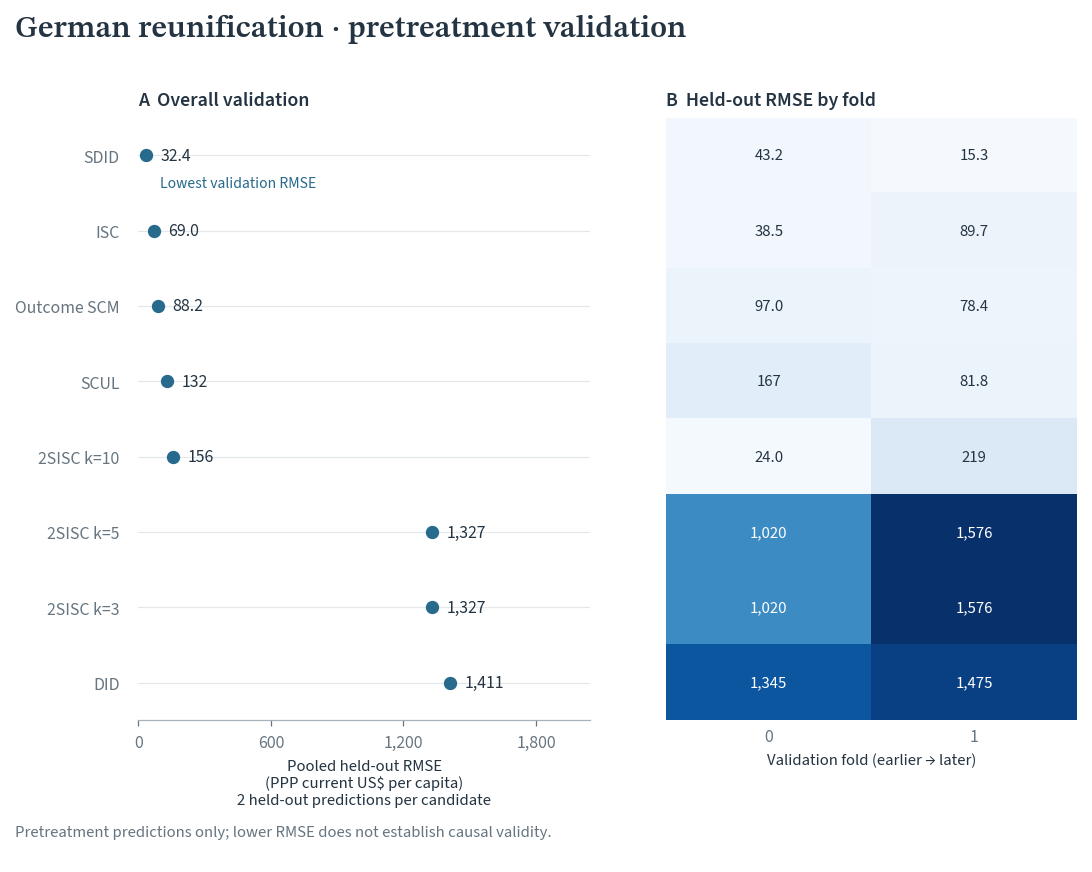

Project exports · `outputs/empirical_examples/germany/germany-validation.pdf` · `outputs/empirical_examples/germany/germany-validation.svg` · `outputs/empirical_examples/germany/germany-validation.png` · [Literature source](https://economics.mit.edu/sites/default/files/publications/Comparative%20Politics%20and%20the%20Synthetic%20Control.pdf#page=10)

,Category,Message,Count
0,RuntimeWarning,"scul reference backend: Warning message:\nIn max(lambdapath[id1se], na.rm = TRUE) :\n no non-missing arguments to max; returning -Inf",1
1,RuntimeWarning,SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata,2


,rank,validation_rmse,mae,bias,n_predictions,n_folds
model,,,,,,
SDID,1,32.413294,29.254407,29.254407,2,2
ISC,2,69.034189,64.117573,64.117573,2,2
Outcome SCM,3,88.193153,87.702526,-87.702526,2,2
SCUL,4,131.726166,124.574915,-124.574915,2,2
2SISC k=10,5,156.041208,121.692615,-121.692615,2,2
2SISC k=5,6,1327.436627,1298.000000,1298.000000,2,2
2SISC k=3,7,1327.436627,1298.000000,1298.000000,2,2
DID,8,1411.481855,1409.965363,1409.965363,2,2
,model,fold,training_end,validation_start,validation_end,validation_rmse


In [7]:
candidates = {
    'Outcome SCM': SyntheticControl,
    'SCUL': partial(SCUL, initial_window=initial, horizon=horizon),
    'ISC': IndividualSC,
    'SDID': SyntheticDID,
    'DID': DifferenceInDifferences,
    **{f'2SISC k={k}': partial(TwoStageIndividualSC, n_neighbors=k)
       for k in (3, 5, 10)},
}
validation_start = max(panel.n_pre // 2, initial + horizon)
validation_horizon = max(1, (panel.n_pre - validation_start) // 3)
with warnings.catch_warnings(record=True) as validation_warnings:
    selection = select_estimator(
        panel, candidates, initial_window=validation_start,
        horizon=validation_horizon,
    )
validation = selection.validation
validation.summary.to_csv(output_dir / f'{name}-validation-summary.csv')
validation.scores.to_csv(output_dir / f'{name}-validation-folds.csv', index=False)
validation.predictions.to_csv(output_dir / f'{name}-validation-predictions.csv', index=False)
fig, axes = plot_backtest(
    validation, title=figure_details['case'] + ' · pretreatment validation',
    units=figure_details['units'],
)
plt.show()
validation_files = export_figure(fig, 'validation')
display_warnings('Pretreatment validation', validation_warnings)
selected_fit = pd.Series({'Selected estimator': selection.selected_name,
                          'Full-panel selected ATT': selection.estimate.att}, name='Selection')
selected_fit.to_csv(output_dir / f'{name}-selection.csv', index_label='statistic')
display_audit(
    'Validation scores, fold definitions and selected fit',
    validation.summary,
    validation.scores[['model', 'fold', 'training_end', 'validation_start',
                       'validation_end', 'validation_rmse']],
    selected_fit,
)

## Dependence on donor eligibility

Each point removes one eligible donor and fully refits the estimator. Scenario ranges are not confidence intervals.

<details>
<summary>Donor exclusions, complete refitting and interpretation</summary>

Remove **every eligible donor in turn** and completely refit three distinct
estimator families: outcome SCM, the authors' two-stage ISC specification,
and SDID. 2SISC repeats nearest-neighbor screening after each exclusion.
This includes donors whose baseline weight was zero; no old weights are
simply renormalized. The API accepts the other supported methods and
named donor groups using the same protocol.

The figure shows the baseline, every refitted ATT, and the largest absolute
change. Scenario ranges are **not confidence intervals**. Neither a stable
result nor a sign reversal establishes whether a donor is causally valid.
These diagnostics should inform the study design, not selection of a
donor pool that produces a preferred effect.

</details>

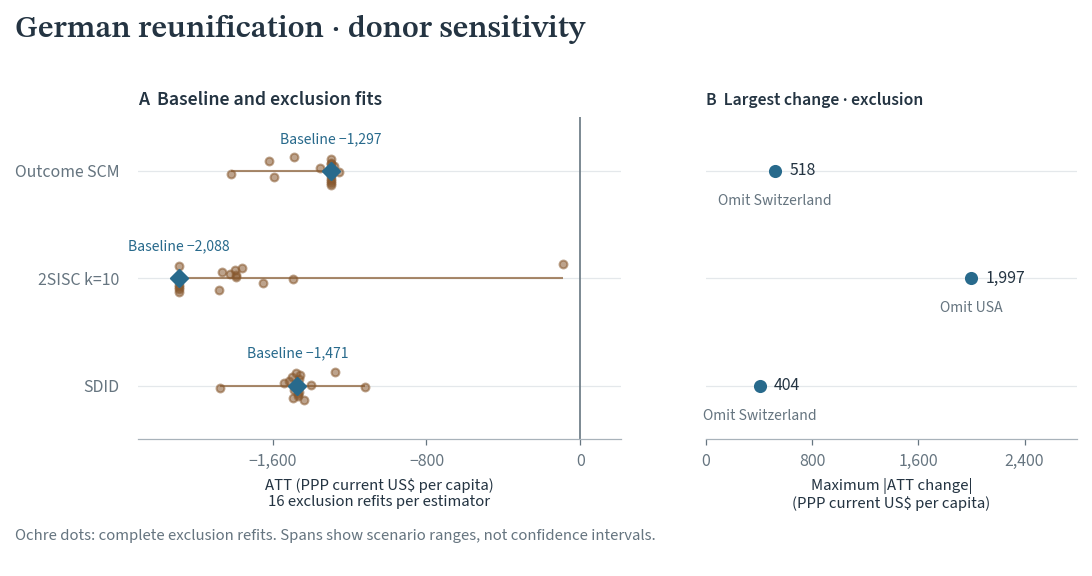

Project exports · `outputs/empirical_examples/germany/germany-donor-sensitivity.pdf` · `outputs/empirical_examples/germany/germany-donor-sensitivity.svg` · `outputs/empirical_examples/germany/germany-donor-sensitivity.png` · [Literature source](https://economics.mit.edu/sites/default/files/publications/Comparative%20Politics%20and%20the%20Synthetic%20Control.pdf#page=10)

,Category,Message,Count
0,RuntimeWarning,SDID reached max_iter (10000) before the objective-decrease stopping rule; increase SyntheticDID(max_iter=...) and inspect the fitted estimate's omega_solver/lambda_solver metadata,17


,baseline_att,min_att,max_att,max_abs_change,worst_scenario,n_scenarios
model,,,,,,
Outcome SCM,-1297.473159,-1815.063287,-1256.417316,517.590128,omit:Switzerland,16
2SISC k=10,-2088.175055,-2088.175055,-91.571429,1996.603626,omit:USA,16
SDID,-1471.394896,-1875.463940,-1119.091749,404.069043,omit:Switzerland,16


In [8]:
with warnings.catch_warnings(record=True) as sensitivity_warnings:
    sensitivity = donor_sensitivity(panel, {
        'Outcome SCM': SyntheticControl,
        '2SISC k=10': partial(TwoStageIndividualSC, n_neighbors=10),
        'SDID': SyntheticDID,
    })
sensitivity.table.to_csv(output_dir / f'{name}-donor-sensitivity.csv', index=False)
sensitivity.summary.to_csv(output_dir / f'{name}-donor-sensitivity-summary.csv')
fig, axes = plot_donor_sensitivity(
    sensitivity, title=figure_details['case'] + ' · donor sensitivity',
    units=figure_details['units'],
)
plt.show()
sensitivity_files = export_figure(fig, 'donor-sensitivity')
display_warnings('Donor exclusions', sensitivity_warnings)
display_audit('Donor sensitivity summary', sensitivity.summary)

## SDID placebo inference and numerical convergence

The original synthdid placebo variance estimator refits donor and time
weights in each of 200 resamples. The seed is fixed. These standard errors
apply to SDID alone; they are not intervals for the other methods.
The bootstrap and jackknife are undefined with only one treated unit.
California uses the authors' exact R sampling plan (seed 12345),
reproducing the paper's standard error 8.4 at its printed precision.
The other examples use NumPy seed 0 for reproducible new applications.

The authors' 10,000-iteration cap can stop some draws before their
objective-decrease criterion is met. We retain that reference result,
then repeat **the identical 200 resamples** with up to 1,000,000 final-stage
iterations and require every resampled weight fit to meet the original
criterion. Penalties, tolerance, sparsification and starting weights
are unchanged. The larger cap is a numerical extension of the reference
software, not its exact finite-iteration replication.

The table compares both standard errors and capped-draw counts. The
original-cap SDID point estimate remains fixed for this comparison;
the strict check applies to resampled weight fits. Meeting the original
objective-decrease rule is not a global optimality certificate; dual
gaps and draw-level diagnostics are exported for inspection. Reference-cap
warnings remain visible; an unresolved extended fit stops the notebook.

In [9]:
with warnings.catch_warnings(record=True) as inference_warnings:
    if paper_uncertainty is not None:
        np.testing.assert_allclose(results['Synthetic DID'].att, reference.att, atol=1e-12)
        reference_uncertainty = paper_uncertainty
    else:
        reference_uncertainty = SyntheticDID().inference(
            panel, method='placebo', replications=200, random_state=0,
            estimate=results['Synthetic DID'],
        )
    uncertainty = SyntheticDID().inference(
        panel, method='placebo', replications=200,
        estimate=results['Synthetic DID'],
        resamples=reference_uncertainty.resamples,
        max_iter=1_000_000, require_convergence=True,
    )
np.testing.assert_array_equal(uncertainty.resamples, reference_uncertainty.resamples)
assert uncertainty.metadata['capped_draws'] == 0
budget_comparison = pd.DataFrame([
    {
        'Run': label,
        'Final-stage iteration cap': fit.metadata['max_iter'],
        'Capped draws': fit.metadata['capped_draws'],
        'Placebo standard error': fit.standard_error,
        'SE change from reference cap': fit.standard_error - reference_uncertainty.standard_error,
        'Largest absolute draw change': np.max(np.abs(fit.draws - reference_uncertainty.draws)),
    }
    for label, fit in [('Reference cap', reference_uncertainty), ('Extended cap', uncertainty)]
]).set_index('Run')
capped = reference_uncertainty.metadata['capped_draws']
if capped:
    print(f'Original SDID iteration cap reached in {capped} of '
          f'{len(reference_uncertainty.draws)} draws before the stopping rule.')
display(budget_comparison)
display_warnings('SDID inference', inference_warnings)
budget_comparison.to_csv(output_dir / f'{name}-sdid-budget-comparison.csv')
convergence = pd.concat({
    label: pd.json_normalize(fit.metadata['solver_diagnostics'])
    for label, fit in [('Reference cap', reference_uncertainty), ('Extended cap', uncertainty)]
}, names=['Run', 'Draw']).reset_index()
convergence.to_csv(output_dir / f'{name}-sdid-convergence.csv', index=False)
inference = pd.Series({
    'SDID ATT': results['Synthetic DID'].att,
    'Placebo standard error': uncertainty.standard_error,
    '95% normal interval': uncertainty.confidence_interval(),
    'Replications': 200,
    'Final-stage iteration cap': uncertainty.metadata['max_iter'],
    'Capped resample fits': uncertainty.metadata['capped_draws'],
}, name='SDID inference')
display(inference)
inference.to_csv(output_dir / f'{name}-sdid-inference.csv')
np.savetxt(output_dir / f'{name}-sdid-resamples.csv', uncertainty.resamples, delimiter=',', fmt='%d')
np.savetxt(output_dir / f'{name}-sdid-draws.csv', uncertainty.draws, delimiter=',')
np.savetxt(output_dir / f'{name}-sdid-reference-draws.csv', reference_uncertainty.draws, delimiter=',')

Original SDID iteration cap reached in 114 of 200 draws before the stopping rule.


,Final-stage iteration cap,Capped draws,Placebo standard error,SE change from reference cap,Largest absolute draw change
Run,,,,,
Reference cap,10000,114,1488.216226,0.000000,0.000000
Extended cap,1000000,0,1488.658831,0.442605,4.810563


,Category,Message,Count
0,RuntimeWarning,"SDID inference: 114 of 200 draws reached max_iter (10000) before the objective-decrease stopping rule (omega: 114, lambda: 0). Increase the resample budget explicitly with inference(max_iter=...); with estimate=..., the default budget is inherited from that fit. Inspect metadata['solver_diagnostics'] for the stopping details.",1


SDID ATT                                                -1471.394896
Placebo standard error                                   1488.658831
95% normal interval          (-4389.112590513887, 1446.322797539317)
Replications                                                     200
Final-stage iteration cap                                    1000000
Capped resample fits                                               0
Name: SDID inference, dtype: object

## Inspect the donor coefficients

These are the fifteen donors with the largest absolute coefficient in
any method, not an exhaustive donor list. The coefficients are not
renormalized. SCUL and some augmented/robust estimates can have negative
weights or weight sums different from one. Intercepts and SDID time
weights are separate components; this table does not represent them.

In [10]:
weights = pd.concat({label: fit.weights for label, fit in results.items()}, axis=1)
weights = weights.loc[weights.abs().max(axis=1).sort_values(ascending=False).index]
weights.to_csv(output_dir / f'{name}-donor-weights.csv', index_label='donor')
pd.DataFrame(warning_rows, columns=['Section', 'Category', 'Message', 'Count']).to_csv(
    output_dir / f'{name}-warnings.csv', index=False,
)
weights.head(15).round(4)

,Outcome SCM,Predictor SCM (three pre-period means),Ridge-augmented SCM,Penalized SCM (0.01),"Robust SCM (rank 3, ridge 0.1)",Differenced SCM,SCUL,ISC (full donor pool),2SISC (nearest 10),Synthetic DID,DID
Austria,0.3232,0.0895,0.2839,0.4234,0.0651,0.2641,0.4609,0.1912,0.0665,0.1070,0.0625
USA,0.3426,0.1392,0.3056,0.3069,0.0893,0.3122,0.3034,0.2197,0.4016,0.1645,0.0625
Switzerland,0.1079,0.2082,0.0754,0.0000,0.0406,0.0542,0.0000,0.1256,0.0000,0.1536,0.0625
Italy,0.0613,0.0823,0.1821,0.0000,0.0525,0.0681,0.1555,0.0907,0.0665,0.0725,0.0625
Denmark,0.0000,0.0313,0.0158,0.1676,0.0832,0.0909,0.0000,0.0620,0.0665,0.0649,0.0625
Spain,0.0000,0.0000,-0.1633,0.0000,0.0735,0.0000,0.0000,0.0000,0.0000,0.0000,0.0625
Norway,0.0277,0.1336,0.0352,0.0000,0.1478,0.0003,0.0000,0.0661,0.0665,0.0958,0.0625
Japan,0.0000,0.1072,-0.1369,0.0000,0.0394,0.0000,0.0000,0.0014,0.0665,0.0577,0.0625
Greece,0.0988,0.0000,0.1187,0.0000,0.0494,0.0340,0.0406,0.0294,0.0000,0.0000,0.0625
France,0.0385,0.0651,0.1089,0.0000,0.0659,0.0000,0.0307,0.1085,0.0665,0.0767,0.0625


## Interpretation, exports and reproducibility

Negative effects mean the observed outcome is below its estimated
untreated path. These are point estimates under different restrictions,
tuning choices and identifying assumptions. They are not an uncertainty
distribution. The historical reference check is distinct from the new
comparison specifications and their stated tuning choices.

Each figure is exported at **7.2 inches wide** in three formats: PDF with
embedded fonts, SVG with editable text, and 300 dpi PNG. The local paths
are printed beside each embedded figure. Generated figures, CSV summaries,
and diagnostic files stay outside version control; rerunning the notebook
recreates them. Use vector formats for manuscripts and adjust figure size, labels
and captions through the plotting API before exporting to a journal's
requirements. Nothing depends on system fonts or an external TeX install.

`pysynth.placebo_test` provides in-space RMSPE-ratio diagnostics and a
rank statistic. The treated and placebo fits have different donor-pool sizes,
so exchangeability alone does not make this an exact randomization test.
It is not synthdid's placebo
variance estimator. The original SCUL scanner-data and ISC/costofcare
survey studies are not reproduced here. Re-run from a fresh kernel to
reproduce the source checks, estimates and figures together.